<a href="https://colab.research.google.com/github/muysgarden/MARISTELA-CSST102-CS3B/blob/main/CSST102_Assessment_Task_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

**Task 1: Dataset Exploration and Analysis**

In [8]:
df = pd.read_csv("spam.csv", encoding="latin-1")

print("First 10 records:")
display(df.head(10))

print("Dataset dimensions:", df.shape)

First 10 records:


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
5,spam,FreeMsg Hey there darling it's been 3 week's n...,NaN,NaN,NaN
6,ham,Even my brother is not like to speak with me. ...,NaN,NaN,NaN
7,ham,As per your request 'Melle Melle (Oru Minnamin...,NaN,NaN,NaN
8,spam,WINNER!! As a valued network customer you have...,NaN,NaN,NaN
9,spam,Had your mobile 11 months or more? U R entitle...,NaN,NaN,NaN


Dataset dimensions: (5572, 5)


Check missing values and duplicate messages

In [10]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate messages:")
print(df.duplicated(subset=["v2"]).sum())

Missing values:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

Duplicate messages:
403


Remove unnecessary columns and rename the columns

In [11]:
df = df[["v1", "v2"]].copy()

df.rename(columns={
    "v1": "class",
    "v2": "message"
}, inplace=True)

df.dropna(subset=["class", "message"], inplace=True)
df.drop_duplicates(subset=["message"], inplace=True)

df.reset_index(drop=True, inplace=True)

display(df.head(10))

,class,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


Count spam and ham messages

In [12]:
counts = df["class"].value_counts()
percentages = df["class"].value_counts(normalize=True) * 100

summary = pd.DataFrame({
    "Count": counts,
    "Percentage": percentages.round(2)
})

display(summary)

,Count,Percentage
class,,
ham,4516,87.37
spam,653,12.63


Create a bar chart

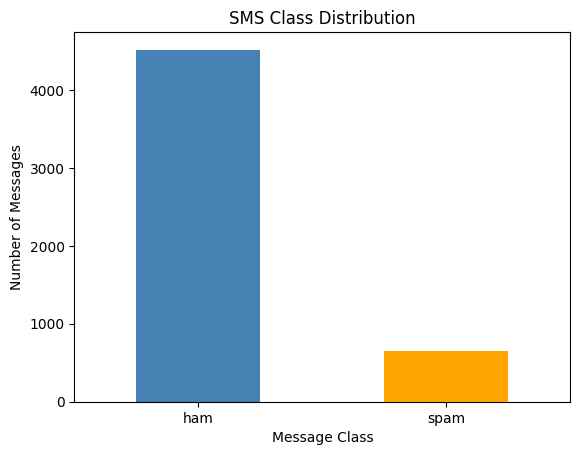

In [13]:
counts.plot(
    kind="bar",
    color=["steelblue", "orange"]
)

plt.title("SMS Class Distribution")
plt.xlabel("Message Class")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()

**Analysis question**

*Question: Is the dataset balanced or imbalanced?*

- A balanced dataset has approximately equal numbers of spam and ham messages. An imbalanced dataset has substantially more examples of one class.

- For example the actual count of the each class in this data set, the ham messages make up 87.37% and spam messages make up 12.63%, the dataset is imbalanced because ham is the majority class.

**Task 2: NLP Text Preprocessing**

In [14]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download("stopwords")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

Create the preprocessing function

In [15]:
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def preprocess_text(text):
    # 1. Convert to lowercase
    text = text.lower()

    # 2. Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # 3. Remove punctuation, special characters and digits
    text = re.sub(r'[^a-z\s]', ' ', text)

    # 4. Tokenization
    tokens = text.split()

    # 5. Remove stopwords
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # 6. Apply stemming
    tokens = [stemmer.stem(word) for word in tokens]

    return " ".join(tokens)

Apply preprocessing to the dataset

In [16]:
df["clean_message"] = df["message"].apply(preprocess_text)

display(df[["message", "clean_message"]].head(5))

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st m...
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though


**Analysis question**

*Question: How can text preprocessing affect Naive Bayes classification performance?*

- Preprocessing can help by reducing unnecessary variations in the text. For example, converting FREE, Free, and free into lowercase makes them consistent. Stemming can also combine related word forms.

- However, preprocessing can sometimes remove useful information. Removing digits may discard phone numbers or prize amounts that could indicate spam. This is why preprocessing choices can affect model performance.

**Task 3: Text Feature Extraction**

Create both feature representations

In [20]:
count_demo = CountVectorizer()
tfidf_demo = TfidfVectorizer()

X_count_demo = count_demo.fit_transform(df["clean_message"])
X_tfidf_demo = tfidf_demo.fit_transform(df["clean_message"])

for name, vectorizer, matrix in [
    ("CountVectorizer", count_demo, X_count_demo),
    ("TF-IDF", tfidf_demo, X_tfidf_demo)
]:
    print("\n", name)
    print("Matrix dimensions:", matrix.shape)
    print("Vocabulary size:", len(vectorizer.vocabulary_))
    print("10 feature names:",
          vectorizer.get_feature_names_out()[:10])


 CountVectorizer
Matrix dimensions: (5169, 6178)
Vocabulary size: 6178
10 feature names: ['aa' 'aah' 'aaniy' 'aaooooright' 'aathi' 'ab' 'abbey' 'abdomen' 'abeg'
 'abel']

 TF-IDF
Matrix dimensions: (5169, 6178)
Vocabulary size: 6178
10 feature names: ['aa' 'aah' 'aaniy' 'aaooooright' 'aathi' 'ab' 'abbey' 'abdomen' 'abeg'
 'abel']


Understand the results

*   Matrix dimensions: Number of messages × number of word features.
*   Vocabulary size: Number of distinct words recognized by the vectorizer.
* Feature names: Words that become numerical features.

**Analysis question**

Explain the difference between word frequency and TF-IDF weighting.
*Which representation might be more suitable for spam classification, and why?*

- CountVectorizer measures how often words occur, while TF-IDF gives relatively more importance to words that are distinctive across messages.

- For spam classification, TF-IDF might help emphasize distinctive words, but CountVectorizer can also perform very well with Multinomial Naive Bayes.

**Task 4: Naive Bayes Model Development**

Split dataset

In [21]:
X = df["clean_message"]
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 3618
Testing records: 1551


Train Model A — CountVectorizer

In [22]:
count_vectorizer = CountVectorizer()

X_train_count = count_vectorizer.fit_transform(X_train)
X_test_count = count_vectorizer.transform(X_test)

model_a = MultinomialNB()
model_a.fit(X_train_count, y_train)

pred_a = model_a.predict(X_test_count)

print("Model A trained successfully!")

Model A trained successfully!


Train Model B — TF-IDF

In [23]:
tfidf_vectorizer = TfidfVectorizer()

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

model_b = MultinomialNB()
model_b.fit(X_train_tfidf, y_train)

pred_b = model_b.predict(X_test_tfidf)

print("Model B trained successfully!")

Model B trained successfully!


**Task 5: Model Evaluation and Comparison**

Calculate evaluation metrics

In [27]:
def evaluate_model(y_true, y_pred):
    cm = confusion_matrix(
        y_true, y_pred,
        labels=['ham', 'spam']
    )

    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, pos_label='spam', zero_division=0),
        'Recall': recall_score(y_true, y_pred, pos_label='spam', zero_division=0),
        'F1-score': f1_score(y_true, y_pred, pos_label='spam', zero_division=0),
        'False Positives': cm[0, 1],
        'False Negatives': cm[1, 0]
    }

results_a = evaluate_model(y_test, pred_a)
results_b = evaluate_model(y_test, pred_b)

comparison = pd.DataFrame({
    'Model A': results_a,
    'Model B': results_b
})

print(comparison.round(4))

                 Model A  Model B
Accuracy          0.9839   0.9594
Precision         0.9572   0.9854
Recall            0.9133   0.6888
F1-score          0.9347   0.8108
False Positives   8.0000   2.0000
False Negatives  17.0000  61.0000


Display confusion matrices

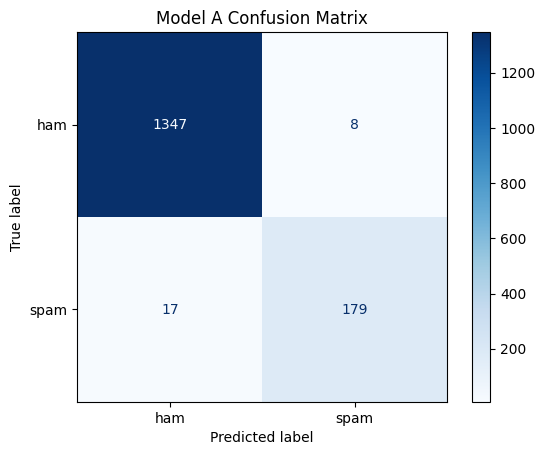

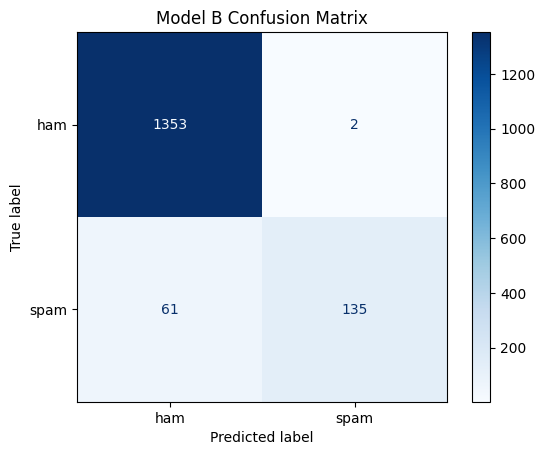

In [28]:
for name, predictions in [
    ('Model A', pred_a),
    ('Model B', pred_b)
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=['ham', 'spam'],
        cmap='Blues'
    )
    plt.title(name + ' Confusion Matrix')
    plt.show()

Determine the better model

In [29]:
if results_a['F1-score'] >= results_b['F1-score']:
    best_model = model_a
    best_vectorizer = count_vectorizer
    best_name = "Model A"
else:
    best_model = model_b
    best_vectorizer = tfidf_vectorizer
    best_name = "Model B"

print("Better model based on F1-score:", best_name)

Better model based on F1-score: Model A


**Analysis question**: *Which model performs better? Explain why precision and recall are important for spam detection, particularly when legitimate messages may be incorrectly classified as spam.*

- Basing on my comparison and evaluation I have determine that Model A performs better

**Task 6 — Testing with Unseen Messages**

Enter the five messages

In [30]:
new_messages = [
    "Congratulations! You have won a free cash prize.",
    "Good morning, our class starts at 8 AM tomorrow.",
    "Claim your reward now by clicking this link.",
    "Please submit your assignment before Friday.",
    "URGENT! You have been selected to receive a cash bonus."
]

Preprocess and predict

In [31]:
clean_new = [preprocess_text(msg) for msg in new_messages]

new_features = best_vectorizer.transform(clean_new)

predictions = best_model.predict(new_features)
probabilities = best_model.predict_proba(new_features)

predicted_probabilities = probabilities.max(axis=1)

output = pd.DataFrame({
    'SMS Message': new_messages,
    'Prediction': predictions,
    'Predicted Probability': predicted_probabilities
})

print(output.to_string(index=False))

                                            SMS Message Prediction  Predicted Probability
       Congratulations! You have won a free cash prize.       spam               0.999984
       Good morning, our class starts at 8 AM tomorrow.        ham               0.999971
           Claim your reward now by clicking this link.       spam               0.999841
           Please submit your assignment before Friday.        ham               0.943379
URGENT! You have been selected to receive a cash bonus.       spam               0.999998
